# Phase 3 — Exploratory Analysis: Label, Lag Sweep and Quarter-Level Re-test

**Purpose.** Build the quarterly decline label on the **Train window only**, then ask how the mortgage-rate change relates to it. `sql/004_phase3_eda.sql` does the heavy lifting on the server:

1. the **label**: a county-quarter counts as a decline when its ZHVI fell by more than 2% from the previous quarter end;
2. the **lag sweep**: the correlation of the label with the rate change at lags of 1, 2, 3, 6, 9 and 12 months;
3. the same correlation **by quarter**, which is the honest sample size.

This notebook adds what SQL cannot easily give: p-values and 95% confidence intervals (Fisher z-transformation), the plots, and the sign check against the hypothesis stated in advance.

**Training data only.** `004` reads only `train_monthly`, so no decision made here can be informed by the Embargo or Test months.

**Decisions**

| Decision | Choice | Why |
|---|---|---|
| Quarter representation | Quarter-end month only. A quarter with an empty end month gets no label, and neither does the quarter after it. | Every label is a true quarter-to-quarter change, and a gap is never labelled "no decline" |
| Decline threshold | Strictly more than 2% | Matches the business question |
| Rate change | Percentage-point difference, `rate(t) - rate(t - lag)` | Rates are already percentages, so a one-point move means the same at any level. Section 7 compares it with relative change |
| Alignment | Each label quarter is paired with the rate change at the end of the quarter **before** it | Predicting one quarter ahead may only use what is known beforehand |
| Lag used downstream | 12 months, the largest correlation of this sweep | Chosen on Train only. At quarter level the lags cannot be told apart, so it is a convention and not a finding |

**Expected hypothesis, stated before running.** A rising mortgage rate should make a decline *more* likely, so the expected sign of the correlation is **positive**.

## 1. Setup and connection

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sqlalchemy import create_engine, text
from dotenv import load_dotenv

sns.set_theme(style="whitegrid")
load_dotenv(override=True)

DB_USER = os.environ.get("PGUSER", "postgres")
DB_PASSWORD = os.environ.get("PGPASSWORD", "")
DB_HOST = os.environ.get("PGHOST", "localhost")
DB_PORT = os.environ.get("PGPORT", "5432")
DB_NAME = os.environ.get("PGDATABASE", "housing_risk_sql")

engine = create_engine(
    f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
)


def run_sql_file(name):
    """Run a whole SQL file through the raw database cursor, with no parameters."""
    path = Path("../sql") / name
    raw = engine.raw_connection()
    try:
        cur = raw.cursor()
        cur.execute(path.read_text(encoding="utf-8"))
        raw.commit()
    except Exception:
        raw.rollback()
        raise
    finally:
        raw.close()
    print(f"ran {path}")


def add_inference(df, r_col="correlation", n_col="n_rows"):
    """Add a p-value (t-distribution) and a 95% interval (Fisher z) to a table of correlations."""
    df = df.copy()
    r, n = df[r_col].to_numpy(dtype=float), df[n_col].to_numpy(dtype=float)
    t = r * np.sqrt((n - 2) / (1 - r**2))
    df["p_value"] = 2 * stats.t.sf(np.abs(t), n - 2)
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    crit = stats.norm.ppf(0.975)
    df["ci_low"], df["ci_high"] = np.tanh(z - crit * se), np.tanh(z + crit * se)
    return df


os.makedirs("../outputs", exist_ok=True)
with engine.connect() as conn:
    print(conn.execute(text("SELECT current_database();")).scalar())
    for name in ("train_monthly", "mortgage_monthly"):
        assert conn.execute(text("SELECT to_regclass(:n)"), {"n": name}).scalar(), (
            f"STOP: {name} not found. Run notebook 01 and sql/003_phase2_split.sql first.")
print("train_monthly and mortgage_monthly found.")

capstone_sql_variant
train_monthly and mortgage_monthly found.


## 2. Run `004_phase3_eda.sql` and check the label

The script drops and rebuilds its own tables, so it is safe to re-run. The check below confirms that no label spans more than one quarter, and prints the label rows, the decline rate and the number of counties.

In [2]:
run_sql_file("004_phase3_eda.sql")

label = pd.read_sql(
    """
    SELECT COUNT(*) AS n_rows, AVG(decline_label) AS positive_rate,
           COUNT(DISTINCT county_fips) AS n_counties,
           SUM(CASE WHEN prev_quarter <> (quarter - INTERVAL '3 months')::date THEN 1 ELSE 0 END) AS n_gap_labels
    FROM train_quarterly_labeled
    """, engine).iloc[0]
print(f"Train label: {int(label.n_rows):,} rows, {100 * label.positive_rate:.2f}% declines, {int(label.n_counties):,} counties")
assert int(label.n_gap_labels) == 0, "A label spans more than one quarter."
print("Every label is a true quarter-to-quarter change.")

ran ..\sql\004_phase3_eda.sql
Train label: 173,277 rows, 4.88% declines, 3,021 counties
Every label is a true quarter-to-quarter change.


**Expected with the Zillow file of October 2026:** 173,277 rows and 4.88% declines. These are the same figures that notebook 01 (Section 8, in pandas) and `sql/006_checks.sql` (check 6a, in SQL) give for the Train window.

## 3. One national rate, about 3,000 counties

The rate change is **one national number per quarter**, shared by every county. So the 170,000 county-quarter rows are not 170,000 independent observations about the rate. This chart makes it visible: each quarter becomes one point, the share of counties with a decline, next to that quarter's 12-month rate change.

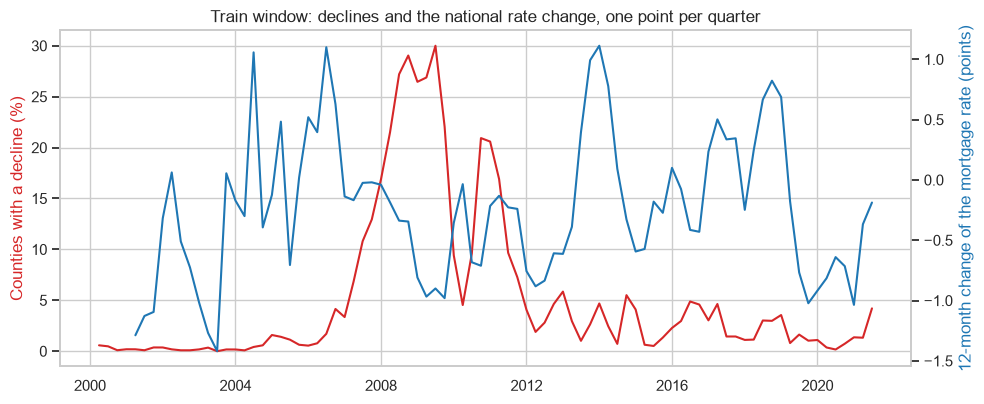

86 quarters in the Train window


In [3]:
per_quarter = pd.read_sql(
    """
    SELECT quarter, AVG(decline_label) AS decline_share, AVG(roc_12m) AS rate_change_12m
    FROM lag_correlation_input
    GROUP BY quarter ORDER BY quarter
    """, engine)
per_quarter["quarter"] = pd.to_datetime(per_quarter["quarter"])

fig, ax1 = plt.subplots(figsize=(10, 4.2))
ax1.plot(per_quarter["quarter"], 100 * per_quarter["decline_share"], color="tab:red", label="Share of counties with a decline")
ax1.set_ylabel("Counties with a decline (%)", color="tab:red")
ax2 = ax1.twinx()
ax2.plot(per_quarter["quarter"], per_quarter["rate_change_12m"], color="tab:blue", label="12-month rate change")
ax2.set_ylabel("12-month change of the mortgage rate (points)", color="tab:blue")
ax2.grid(False)
ax1.set_title("Train window: declines and the national rate change, one point per quarter")
fig.tight_layout()
fig.savefig("../outputs/phase3_positive_rate_over_time.png", dpi=150)
plt.show()
print(f"{len(per_quarter)} quarters in the Train window")

## 4. Row-level lag sweep, with confidence intervals

`004` computed the correlation on the server with `corr()`. Here the p-values and 95% intervals are added. The winner is picked by magnitude alone, and its sign is checked afterwards against the hypothesis, as a face-validity flag and not as a filter.

In [4]:
lag_all = pd.read_sql(
    "SELECT definition, lag_months, correlation, n_rows FROM lag_correlation_results ORDER BY definition, lag_months", engine)
lag = add_inference(lag_all[lag_all["definition"] == "percentage points"].reset_index(drop=True))
lag.round(4)

,definition,lag_months,correlation,n_rows,p_value,ci_low,ci_high
0,percentage points,1,-0.0082,173277,0.0007,-0.0129,-0.0035
1,percentage points,2,-0.0010,173277,0.6832,-0.0057,0.0037
2,percentage points,3,-0.0183,172239,0.0000,-0.0230,-0.0136
3,percentage points,6,-0.0232,171194,0.0000,-0.0279,-0.0185
4,percentage points,9,-0.0409,170145,0.0000,-0.0457,-0.0362
5,percentage points,12,-0.0506,169091,0.0000,-0.0554,-0.0459


In [5]:
EXPECTED_SIGN = "positive"
w = lag.loc[lag["correlation"].abs().idxmax()]
sign = "positive" if w["correlation"] > 0 else "negative"
print(f"Winning lag: {int(w['lag_months'])} months, r = {w['correlation']:.4f} "
      f"(95% CI [{w['ci_low']:.4f}, {w['ci_high']:.4f}]), n = {int(w['n_rows']):,}")
print(f"Expected sign: {EXPECTED_SIGN} | observed: {sign} | match: {sign == EXPECTED_SIGN}")
print()
print("Caution: with n in the hundreds of thousands, even a tiny correlation has a tiny p-value, and the rows are not "
      "independent (section 3). Section 5 repeats the test at quarter level.")

Winning lag: 12 months, r = -0.0506 (95% CI [-0.0554, -0.0459]), n = 169,091
Expected sign: positive | observed: negative | match: False

Caution: with n in the hundreds of thousands, even a tiny correlation has a tiny p-value, and the rows are not independent (section 3). Section 5 repeats the test at quarter level.


## 5. Quarter-level re-test: the honest sample size

Each quarter is one data point: its share of counties with a decline, against that quarter's rate change. The sample size is the number of quarters, about 80, and the intervals widen accordingly.

In [6]:
qlag = add_inference(pd.read_sql(
    "SELECT lag_months, correlation, n_quarters AS n_rows FROM lag_correlation_quarterly ORDER BY lag_months", engine)
).rename(columns={"n_rows": "n_quarters"})

w12 = qlag[qlag["lag_months"] == 12].iloc[0]
print(f"12-month lag, quarter level: r = {w12['correlation']:.3f}, 95% CI [{w12['ci_low']:.3f}, {w12['ci_high']:.3f}], "
      f"p = {w12['p_value']:.2f}, {int(w12['n_quarters'])} quarters")
print(f"Intervals that include zero: {int(((qlag['ci_low'] < 0) & (qlag['ci_high'] > 0)).sum())} of {len(qlag)} lags")
qlag.round(4)

12-month lag, quarter level: r = -0.145, 95% CI [-0.351, 0.074], p = 0.19, 82 quarters
Intervals that include zero: 6 of 6 lags


,lag_months,correlation,n_quarters,p_value,ci_low,ci_high
0,1,-0.0354,86,0.7462,-0.2454,0.1778
1,2,-0.0124,86,0.9096,-0.2237,0.2000
2,3,-0.0570,85,0.6045,-0.2669,0.1581
3,6,-0.0729,84,0.5099,-0.2829,0.1437
4,9,-0.1218,83,0.2728,-0.3288,0.0965
5,12,-0.1452,82,0.1930,-0.3512,0.0741


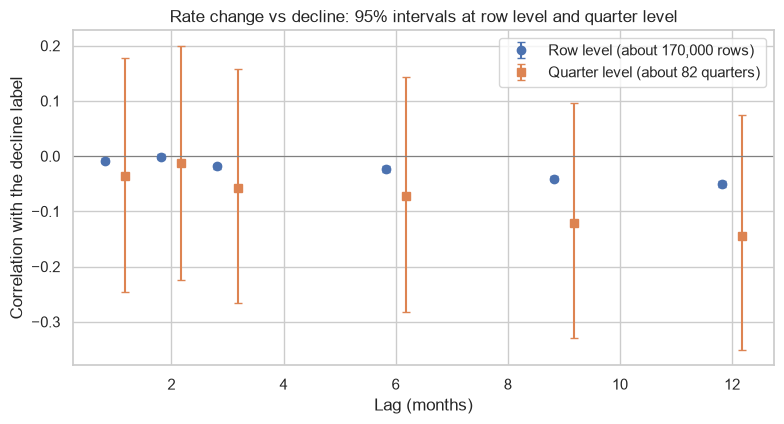

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.4))
off = 0.18
ax.errorbar(lag["lag_months"] - off, lag["correlation"], yerr=[lag["correlation"] - lag["ci_low"], lag["ci_high"] - lag["correlation"]],
            fmt="o", capsize=3, label="Row level (about 170,000 rows)")
ax.errorbar(qlag["lag_months"] + off, qlag["correlation"], yerr=[qlag["correlation"] - qlag["ci_low"], qlag["ci_high"] - qlag["correlation"]],
            fmt="s", capsize=3, label="Quarter level (about 82 quarters)")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Lag (months)")
ax.set_ylabel("Correlation with the decline label")
ax.set_title("Rate change vs decline: 95% intervals at row level and quarter level")
ax.legend()
fig.tight_layout()
fig.savefig("../outputs/phase3_lag_correlation.png", dpi=150)
plt.show()

## 6. Save the results

In [8]:
lag_all.to_csv("../outputs/phase3_lag_correlation_rows.csv", index=False)
lag.to_csv("../outputs/phase3_lag_correlation.csv", index=False)
qlag.to_csv("../outputs/phase3_lag_correlation_quarterly.csv", index=False)
print("Saved the lag tables and two figures to outputs/")

Saved the lag tables and two figures to outputs/


## 7. Study: how the rate change is defined

The same 12-month change of the mortgage rate can be written two ways: in **percentage points**, `rate(t) - rate(t-12)`, or as a **relative change**, `rate(t) / rate(t-12) - 1`. Rates are already percentages, so a rise from 3% to 6% is +3 points but +100% in relative terms, while the same +3 points from 6% to 9% is only +50%. A relative change therefore means something different at every rate level.

First, which definition correlates more strongly with the label, on exactly the same rows?

In [9]:
same_rows = lag_all[lag_all["lag_months"] == 12][["definition", "correlation", "n_rows"]].reset_index(drop=True)
same_rows

,definition,correlation,n_rows
0,percentage points,-0.050628,169091
1,relative change,-0.034731,169091


Second, how far does each definition move outside the range it had during training? The Test period contains the 2022-23 hiking cycle, which never occurs in Train. A model only learns the range it has seen, so a larger gap between the Train maximum and the Test maximum is a larger extrapolation.

In [10]:
rates = pd.read_sql(
    """
    SELECT m.month, m.mortgage_rate, s.split
    FROM mortgage_monthly m
    JOIN (SELECT DISTINCT month, split FROM monthly_split) s USING (month)
    ORDER BY m.month
    """, engine)
rates["percentage points"] = rates["mortgage_rate"] - rates["mortgage_rate"].shift(12)
rates["relative change"] = rates["mortgage_rate"] / rates["mortgage_rate"].shift(12) - 1

rows = []
for definition in ("percentage points", "relative change"):
    tr = rates.loc[rates["split"] == "train", definition].dropna()
    te = rates.loc[rates["split"] == "test", definition].dropna()
    rows.append({"definition": definition, "train_min": tr.min(), "train_max": tr.max(),
                 "test_min": te.min(), "test_max": te.max(), "test_max_over_train_max": te.max() / tr.max()})
pd.DataFrame(rows).round(3)

,definition,train_min,train_max,test_min,test_max,test_max_over_train_max
0,percentage points,-1.420,1.112,-1.192,3.833,3.445
1,relative change,-0.278,0.333,-0.156,1.249,3.757


## 8. Findings

- **The label** has 173,277 rows with 4.88% declines on the Train window. These are the same figures that notebook 01 (Section 8, in pandas) and `sql/006_checks.sql` (check 6a, in SQL) give.
- **The 12-month lag has the largest correlation** at row level: r = -0.0506 (95% interval -0.0554 to -0.0459, n = 169,091). The expected sign was positive, so the sign is **negative**, the opposite of the hypothesis. The effect is small.
- **The intervals above are far too narrow.** The rate change is one national number per quarter, so the rows are not independent. At quarter level the 12-month correlation is r = -0.145 on 82 quarters, with a 95% interval of -0.351 to +0.074 (p = 0.19), which includes zero. The same holds for all six lags. The link is weak and its sign inconclusive, and the lags cannot be told apart statistically, so the 12-month lag is used downstream as a convention and not as a finding.
- **Percentage points beat relative change, but neither removes the extrapolation.** On exactly the same 169,091 rows the correlation is -0.0506 for percentage points and -0.0347 for relative change, so percentage points are used throughout. In the Test period the 12-month change reaches +3.83 points against a Train maximum of +1.11 (3.4 times as large), or +125% against a Train maximum of +33% (3.8 times as large). Both leave the training range, because the 2022-23 hiking cycle has no equivalent in Train, so a model has to extrapolate under either definition.